# Retards et annulations de vols aux États-Unis en 2015

Ce notebook vérifie la qualité des données, puis cherche ce qui explique les retards et les annulations.

In [1]:
import pandas as pd

flights = pd.read_csv("../data/raw/flights.csv", low_memory=False)
len(flights)

5819079

In [2]:
import matplotlib.pyplot as plt

BLEU = "#2a78d6"
COULEURS_CAUSES = {
    "Avion arrivé en retard": "#2a78d6",
    "Compagnie": "#eb6834",
    "Système aérien": "#1baf7a",
    "Météo extrême": "#eda100",
    "Sûreté": "#e87ba4",
}

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

## 1. Nettoyage

### Pourquoi certains vols n'ont-ils pas de retard au départ ?

Hypothèse : ces vols ont été annulés, donc ils ne sont jamais partis. Si c'est vrai, ces cases vides ne sont pas des erreurs, et il ne faut pas les remplacer par 0.

In [3]:
pd.crosstab(flights["DEPARTURE_DELAY"].isna(), flights["CANCELLED"])

CANCELLED,0,1
DEPARTURE_DELAY,,
False,5729195,3731
True,0,86153


**Constat :** tous les retards vides correspondent à des vols annulés. On ne les remplace donc pas par 0.

### Faut-il garder les vols annulés qui ont un retard au départ ?

**Choix : on les garde.** Un long retard au départ pourrait précéder une annulation : les retirer ferait disparaître ce signal. On compare donc leur retard à celui des autres vols.

In [4]:
flights.groupby("CANCELLED")["DEPARTURE_DELAY"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
CANCELLED,,,,,,,,
0,5729195.0,9.3,37.0,-82.0,-5.0,-2.0,7.0,1988.0
1,3731.0,57.5,95.5,-25.0,-2.0,21.0,83.0,1274.0


In [5]:
avec_annules = flights["DEPARTURE_DELAY"].mean()
sans_annules = flights.loc[flights["CANCELLED"] == 0, "DEPARTURE_DELAY"].mean()
round(avec_annules, 2), round(sans_annules, 2)

(np.float64(9.37), np.float64(9.34))

### Quand les causes de retard sont-elles renseignées ?

Hypothèse : les 5 colonnes de causes ne sont remplies que pour les vols arrivés avec au moins 15 minutes de retard.

In [6]:
causes = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]

cause_renseignee = flights[causes].notna().all(axis=1)
retard_15_min = flights["ARRIVAL_DELAY"] >= 15

pd.crosstab(retard_15_min, cause_renseignee)

col_0,False,True
ARRIVAL_DELAY,,
False,4755640,0
True,0,1063439


### La somme des causes correspond-elle au retard à l'arrivée ?

In [7]:
vols_avec_cause = flights[cause_renseignee]
somme_causes = vols_avec_cause[causes].sum(axis=1)

(somme_causes == vols_avec_cause["ARRIVAL_DELAY"]).mean()

np.float64(1.0)

**Constat :** les causes sont renseignées pour tous les vols arrivés avec au moins 15 minutes de retard, et seulement pour eux. Leur somme est toujours égale au retard à l'arrivée.

**Conséquence :** on peut calculer la part de chaque cause, mais uniquement pour ces vols. Une case vide veut dire « cause non renseignée », pas « 0 minute ».

### Les codes d'aéroport des vols existent-ils dans la liste des aéroports ?

Hypothèse : les codes d'octobre sont écrits autrement, donc ce mois-là ne se relie pas à `airports.csv`.

In [8]:
airports = pd.read_csv("../data/raw/airports.csv")

origine_connue = flights["ORIGIN_AIRPORT"].isin(airports["IATA_CODE"])
destination_connue = flights["DESTINATION_AIRPORT"].isin(airports["IATA_CODE"])

pd.crosstab(flights["MONTH"], [origine_connue, destination_connue])

ORIGIN_AIRPORT,False,True
DESTINATION_AIRPORT,False,True
MONTH,,
1,0,469968
2,0,429191
3,0,504312
4,0,485151
5,0,496993
6,0,503897
7,0,520718
8,0,510536


In [9]:
flights.loc[~origine_connue, "ORIGIN_AIRPORT"].value_counts().head()

ORIGIN_AIRPORT
10397    32588
13930    27652
11298    21044
11292    18136
12892    17728
Name: count, dtype: int64

In [10]:
airports[airports[["LATITUDE", "LONGITUDE"]].isna().any(axis=1)]

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
96,ECP,Northwest Florida Beaches International Airport,Panama City,FL,USA,NaN,NaN
234,PBG,Plattsburgh International Airport,Plattsburgh,NY,USA,NaN,NaN
313,UST,Northeast Florida Regional Airport (St. August...,St. Augustine,FL,USA,NaN,NaN


**Constat :** tous les vols d'octobre ont des codes à 5 chiffres, alors que les 11 autres mois utilisent des codes à 3 lettres. Sans correction, octobre disparaît des analyses par aéroport.

### Traduire les codes d'octobre

**Choix :** on récupère ces vols plutôt que de les exclure, car ils représentent 8,4 % des données. Le bureau américain des statistiques de transport (BTS) publie deux tables qui donnent le nom de chaque aéroport : l'une par numéro, l'autre par code à lettres. Le nom sert de lien entre les deux.

In [11]:
# Ces fichiers ne sont pas en UTF-8. keep_default_na=False évite que le code "NA" soit lu comme une case vide.
table_numeros = pd.read_csv("../data/raw/L_AIRPORT_ID.csv", dtype=str, encoding="latin-1", keep_default_na=False)
table_lettres = pd.read_csv("../data/raw/L_AIRPORT.csv", dtype=str, encoding="latin-1", keep_default_na=False)

table_numeros[table_numeros["Code"] == "10397"]

,Code,Description
373,10397,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern..."


In [12]:
est_octobre = flights["MONTH"] == 10
colonnes_aeroport = ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]

codes_octobre = pd.unique(flights.loc[est_octobre, colonnes_aeroport].values.ravel())
codes_autres_mois = pd.unique(flights.loc[~est_octobre, colonnes_aeroport].values.ravel())

correspondance = table_numeros[table_numeros["Code"].isin(codes_octobre)].merge(
    table_lettres[table_lettres["Code"].isin(codes_autres_mois)],
    on="Description",
    suffixes=("_numero", "_lettres"),
)

numeros_sans_traduction = set(codes_octobre) - set(correspondance["Code_numero"])
len(codes_octobre), len(correspondance), numeros_sans_traduction

(307, 306, {'14027'})

### Le code 14027 n'a pas de traduction : lequel est-ce ?

Une route garde la même distance toute l'année. On compare donc les routes de 14027 à celles de PBI (Palm Beach).

In [13]:
traduction = correspondance.set_index("Code_numero")["Code_lettres"]

routes_14027 = flights[flights["ORIGIN_AIRPORT"] == "14027"]
distances_14027 = routes_14027.groupby(routes_14027["DESTINATION_AIRPORT"].map(traduction))["DISTANCE"].median()

routes_pbi = flights[flights["ORIGIN_AIRPORT"] == "PBI"]
distances_pbi = routes_pbi.groupby("DESTINATION_AIRPORT")["DISTANCE"].median()

pd.DataFrame({"14027": distances_14027, "PBI": distances_pbi.reindex(distances_14027.index)})

,14027,PBI
DESTINATION_AIRPORT,,
ATL,545.0,545.0
BDL,1133.0,1133.0
BOS,1197.0,1197.0
BWI,883.0,883.0
CLT,590.0,590.0
DCA,857.0,857.0
DFW,1102.0,1102.0
DTW,1086.0,1086.0
EWR,1023.0,1023.0


**Constat :** les distances sont identiques sur toutes les routes. On ajoute donc 14027 = PBI à la main, puis on traduit les codes.

In [14]:
traduction["14027"] = "PBI"

for colonne in colonnes_aeroport:
    flights[colonne] = flights[colonne].map(traduction).fillna(flights[colonne])

flights["ORIGIN_AIRPORT"].isin(airports["IATA_CODE"]).mean(), flights["DESTINATION_AIRPORT"].isin(airports["IATA_CODE"]).mean()

(np.float64(1.0), np.float64(1.0))

### La traduction est-elle juste ?

On compare la distance de chaque vol d'octobre à la distance de la même route les autres mois. Une mauvaise traduction créerait de grands écarts.

In [15]:
distance_habituelle = (
    flights[~est_octobre]
    .groupby(colonnes_aeroport)["DISTANCE"]
    .median()
    .rename("DISTANCE_HABITUELLE")
)

vols_octobre = flights[est_octobre].join(distance_habituelle, on=colonnes_aeroport)
ecart = (vols_octobre["DISTANCE"] - vols_octobre["DISTANCE_HABITUELLE"]).abs()

ecart.value_counts(dropna=False).sort_index()

0.0    481466
1.0      4579
2.0       117
NaN         3
Name: count, dtype: int64

### Combien de vols sont touchés par les aéroports sans coordonnées ?

In [16]:
sans_coordonnees = airports.loc[airports["LATITUDE"].isna(), "IATA_CODE"]

(flights["ORIGIN_AIRPORT"].isin(sans_coordonnees) | flights["DESTINATION_AIRPORT"].isin(sans_coordonnees)).sum()

np.int64(10020)

**Constat :** 3 aéroports (ECP, PBG, UST) n'ont pas de coordonnées, ce qui touche 10 020 vols, soit 0,17 %.

**Choix :** on garde ces vols dans les chiffres. Ces aéroports n'apparaîtront pas sur la carte, et on le précisera sous celle-ci.

### Les horaires sont-ils utilisables ?

Les horaires sont écrits HHMM : 1430 veut dire 14 h 30, et 5 veut dire 00 h 05. On vérifie d'abord que tous les horaires sont valides.

In [17]:
colonnes_horaires = ["SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "SCHEDULED_ARRIVAL", "ARRIVAL_TIME"]

pd.DataFrame({
    "minimum": flights[colonnes_horaires].min(),
    "maximum": flights[colonnes_horaires].max(),
    "minutes_invalides": (flights[colonnes_horaires] % 100 >= 60).sum(),
    "egal_a_2400": (flights[colonnes_horaires] == 2400).sum(),
})

,minimum,maximum,minutes_invalides,egal_a_2400
SCHEDULED_DEPARTURE,1.0,2359.0,0,0
DEPARTURE_TIME,1.0,2400.0,0,513
SCHEDULED_ARRIVAL,1.0,2400.0,0,2
ARRIVAL_TIME,1.0,2400.0,0,2456


**Constat :** aucun horaire n'a de minutes invalides. La valeur 2400 existe pour minuit dans les heures réelles et d'arrivée, mais jamais dans le départ prévu : l'heure extraite de cette colonne reste donc entre 0 et 23.

### Les horaires sont-ils cohérents avec le retard ?

Heure prévue + retard doit donner l'heure réelle de départ. On compte en minutes depuis minuit, et le modulo 1440 gère le passage de minuit.

In [18]:
def en_minutes(horaire):
    return horaire // 100 * 60 + horaire % 100


depart_calcule = en_minutes(flights["SCHEDULED_DEPARTURE"]) + flights["DEPARTURE_DELAY"]
depart_reel = en_minutes(flights["DEPARTURE_TIME"])
a_un_depart = flights["DEPARTURE_TIME"].notna()

(((depart_calcule - depart_reel) % 1440 == 0)[a_un_depart]).mean()

np.float64(0.9999998255690027)

**Constat :** un seul vol sur 5 732 926 ne respecte pas le calcul. C'est un vol annulé du 24 décembre, prévu à 8 h 04 et parti à 11 h 03, avec un retard indiqué de 1 minute. **Choix :** on le garde, car il ne change aucun résultat.

### Créer l'heure de départ prévue

On garde uniquement l'heure, de 0 à 23, pour comparer les moments de la journée. On utilise l'heure prévue, car elle existe pour tous les vols, même annulés.

In [19]:
flights["HEURE_DEPART_PREVUE"] = flights["SCHEDULED_DEPARTURE"] // 100

flights.groupby("HEURE_DEPART_PREVUE")["DEPARTURE_DELAY"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
HEURE_DEPART_PREVUE,,,
0,14546,7.2,-2.0
1,5107,8.1,-3.0
2,1386,7.3,-3.0
3,767,8.9,-4.0
4,528,10.3,-1.0
5,116029,1.9,-3.0
6,399811,2.1,-3.0
7,388874,3.3,-3.0
8,375889,4.7,-3.0


**Constat :** le retard moyen passe d'environ 2 minutes à 5-6 h à 15 minutes vers 18-20 h. Entre 0 h et 4 h, il y a trop peu de vols pour conclure avec la même confiance.

**Hypothèse à vérifier :** les retards s'accumulent au fil de la journée, car un avion en retard repart en retard.

### Les valeurs extrêmes sont-elles possibles ?

On regarde d'abord le plus petit et le plus grand chiffre de chaque colonne. Une valeur impossible serait par exemple une distance nulle ou un temps de vol négatif.

In [20]:
colonnes_durees = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "AIR_TIME", "ELAPSED_TIME", "DISTANCE"]

flights[colonnes_durees].describe().round(1)

,DEPARTURE_DELAY,ARRIVAL_DELAY,AIR_TIME,ELAPSED_TIME,DISTANCE
count,5732926.0,5714008.0,5714008.0,5714008.0,5819079.0
mean,9.4,4.4,113.5,137.0,822.4
std,37.1,39.3,72.2,74.2,607.8
min,-82.0,-87.0,7.0,14.0,21.0
25%,-5.0,-13.0,60.0,82.0,373.0
50%,-2.0,-5.0,94.0,118.0,647.0
75%,7.0,8.0,144.0,168.0,1062.0
max,1988.0,1971.0,690.0,766.0,4983.0


**Constat :** aucune valeur impossible dans ces colonnes : la distance et le temps de vol sont toujours positifs. Un retard négatif veut dire que le vol est en avance.

### Les plus gros retards sont-ils de vraies données ?

Si le plus gros retard était une erreur de saisie, l'avion ne serait pas arrivé en retard d'autant. On compare donc le retard au départ et à l'arrivée.

In [21]:
colonnes_vol = ["MONTH", "DAY", "AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "DEPARTURE_DELAY", "ARRIVAL_DELAY"]

flights.nlargest(5, "DEPARTURE_DELAY")[colonnes_vol]

,MONTH,DAY,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,ARRIVAL_DELAY
337720,1,23,AA,BHM,DFW,700,1608.0,1988.0,1971.0
3412085,8,1,AA,RIC,DFW,709,1427.0,1878.0,1898.0
4103531,9,13,AA,SAN,DFW,700,1050.0,1670.0,1665.0
5810811,12,31,AA,ABQ,DFW,1041,1410.0,1649.0,1636.0
5279939,11,27,AA,DTW,ORD,1027,1338.0,1631.0,1638.0


**Constat :** le plus gros retard est de 1 988 minutes, soit plus de 33 heures. Il est crédible : le vol prévu à 7 h 00 est parti à 16 h 08 le lendemain et il est arrivé avec 1 971 minutes de retard.

### Combien de vols ont un très gros retard, et pèsent-ils sur la moyenne ?

On compare la moyenne avec et sans les vols partis avec plus de 3 heures de retard.

In [22]:
retard = flights["DEPARTURE_DELAY"]
plus_de_3h = retard > 180

plus_de_3h.sum(), plus_de_3h.mean(), retard.mean(), retard[~plus_de_3h].mean(), retard.quantile([0.5, 0.9, 0.99])

(np.int64(48107),
 np.float64(0.008267115809907376),
 np.float64(9.370158275198389),
 np.float64(7.1309839416171386),
 0.50     -2.0
 0.90     35.0
 0.99    168.0
 Name: DEPARTURE_DELAY, dtype: float64)

**Constat :** 48 107 vols, soit 0,8 %, partent avec plus de 3 heures de retard. Sans eux, la moyenne passe de 9,4 à 7,1 minutes.

**Choix :** on garde ces vols, car ce sont de vrais retards. Comme ils tirent la moyenne vers le haut, on ne s'appuiera pas sur elle seule : on regardera aussi la médiane et la part de vols en retard.

### Y a-t-il des vols en double ?

Un doublon compterait un même vol deux fois. On cherche d'abord les lignes entièrement identiques, puis les lignes qui décrivent le même vol avec des chiffres différents : même jour, même compagnie, même numéro de vol et même heure prévue au même aéroport.

In [23]:
colonnes_identite = ["MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT", "SCHEDULED_DEPARTURE"]

flights.duplicated().sum(), flights.duplicated(subset=colonnes_identite).sum()

(np.int64(0), np.int64(1))

In [24]:
flights[flights.duplicated(subset=colonnes_identite, keep=False)].sort_values(colonnes_identite)[colonnes_identite + ["DESTINATION_AIRPORT", "TAIL_NUMBER", "DEPARTURE_DELAY", "CANCELLED"]].head(10)

,MONTH,DAY,AIRLINE,FLIGHT_NUMBER,ORIGIN_AIRPORT,SCHEDULED_DEPARTURE,DESTINATION_AIRPORT,TAIL_NUMBER,DEPARTURE_DELAY,CANCELLED
3883016,8,29,AA,803,STT,1435,CLT,NaN,NaN,1
3883017,8,29,AA,803,STT,1435,SJU,NaN,NaN,1


**Constat :** aucune ligne n'est entièrement identique. Une seule paire partage la même identité : le vol AA 803 du 29 août, au départ de STT à 14 h 35. Ses deux lignes ont des destinations différentes (CLT et SJU) et sont toutes les deux annulées.

**Choix :** on ne supprime aucune ligne, car rien ne prouve que ce soit un doublon.

## 2. Exploration

### Que devient un vol sur 100 ?

Un vol est dit « en retard » s'il arrive avec au moins 15 minutes de retard. C'est aussi le seuil à partir duquel les causes de retard sont renseignées.

In [25]:
flights["EN_RETARD"] = flights["ARRIVAL_DELAY"] >= 15

annule = flights["CANCELLED"] == 1
devie = flights["DIVERTED"] == 1
a_l_heure = flights["ARRIVAL_DELAY"] < 15

pd.Series({
    "à l'heure": a_l_heure.mean(),
    "en retard": flights["EN_RETARD"].mean(),
    "annulé": annule.mean(),
    "dévié": devie.mean(),
}).mul(100).round(2)

à l'heure    79.92
en retard    18.28
annulé        1.54
dévié         0.26
dtype: float64

**Constat :** sur 100 vols, environ 80 arrivent à l'heure, 18 arrivent en retard, 1,5 est annulé et 0,3 est dévié.

### Certains mois sont-ils pires que d'autres ?

La part de vols en retard est calculée sur les vols arrivés, et la part d'annulations sur tous les vols.

In [26]:
arrive = flights["ARRIVAL_DELAY"].notna()

par_mois = flights.groupby("MONTH").agg(
    vols=("MONTH", "size"),
    pct_annules=("CANCELLED", "mean"),
)
par_mois["pct_annules"] = (par_mois["pct_annules"] * 100).round(2)
par_mois["pct_en_retard"] = (flights[arrive].groupby("MONTH")["EN_RETARD"].mean() * 100).round(1)

par_mois

,vols,pct_annules,pct_en_retard
MONTH,,,
1,469968,2.55,21.0
2,429191,4.78,23.3
3,504312,2.18,19.4
4,485151,0.93,17.2
5,496993,1.15,18.3
6,503897,1.81,23.5
7,520718,0.92,20.9
8,510536,0.99,18.7
9,464946,0.45,13.0


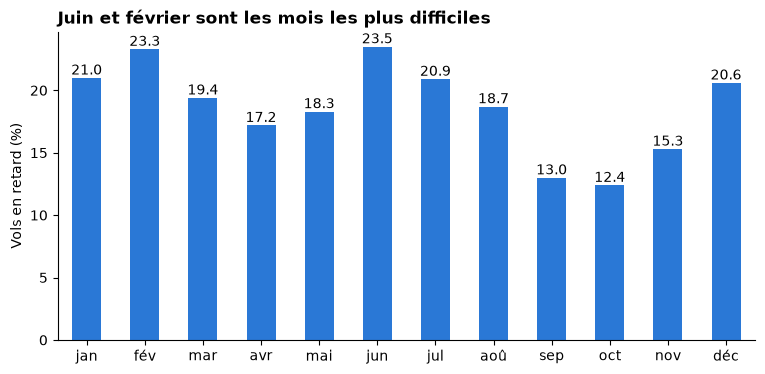

In [27]:
mois_courts = ["jan", "fév", "mar", "avr", "mai", "jun", "jul", "aoû", "sep", "oct", "nov", "déc"]

ax = par_mois.set_axis(mois_courts)["pct_en_retard"].plot.bar(color=BLEU, rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f")
ax.set_title("Juin et février sont les mois les plus difficiles")
ax.set_ylabel("Vols en retard (%)")
plt.show()

**Constat :** le risque de retard varie presque du simple au double selon le mois : 23,5 % en juin contre 12,4 % en octobre. Février combine beaucoup de retards (23,3 %) et le plus d'annulations (4,78 %). Septembre et octobre sont les mois les plus calmes.

**Hypothèse à vérifier :** la météo d'hiver expliquerait février, et les orages ou le trafic d'été expliqueraient juin.

### D'où viennent les minutes de retard ?

Chaque vol arrivé avec au moins 15 minutes de retard répartit ses minutes entre 5 causes. On additionne ces minutes sur toute l'année.

In [28]:
noms_causes = {
    "LATE_AIRCRAFT_DELAY": "Avion arrivé en retard",
    "AIRLINE_DELAY": "Compagnie",
    "AIR_SYSTEM_DELAY": "Système aérien",
    "WEATHER_DELAY": "Météo extrême",
    "SECURITY_DELAY": "Sûreté",
}
colonnes_causes = list(noms_causes)

(flights[colonnes_causes].sum() / flights[colonnes_causes].sum().sum() * 100).rename(noms_causes).round(1)

Avion arrivé en retard    39.8
Compagnie                 32.2
Système aérien            22.9
Météo extrême              4.9
Sûreté                     0.1
dtype: float64

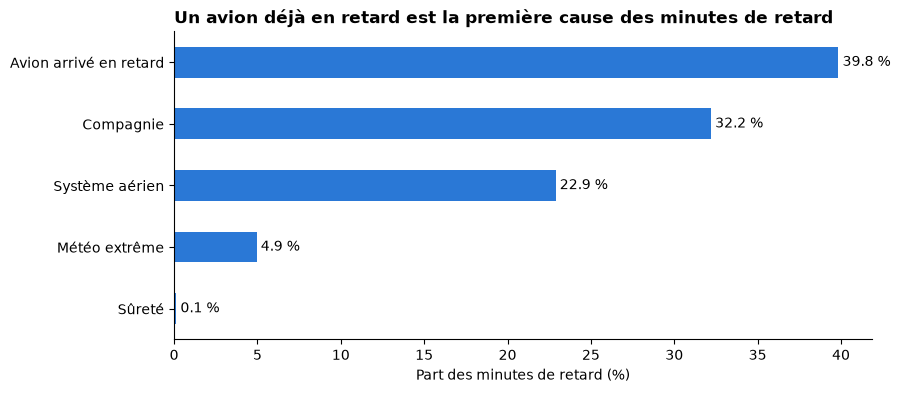

In [29]:
parts_causes = (flights[colonnes_causes].sum() / flights[colonnes_causes].sum().sum() * 100).rename(noms_causes).sort_values()

ax = parts_causes.plot.barh(color=BLEU)
ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3)
ax.set_title("Un avion déjà en retard est la première cause des minutes de retard")
ax.set_xlabel("Part des minutes de retard (%)")
plt.show()

**Constat :** la première cause est un avion déjà en retard sur son vol précédent (39,8 % des minutes), devant la compagnie (32,2 %) et le système aérien (22,9 %). La météo extrême ne pèse que 4,9 %.

**Limite :** « avion arrivé en retard » ne dit pas ce qui a causé le premier retard de la chaîne.

### Quelle cause augmente selon le mois et selon l'heure ?

On compte les minutes de retard de chaque cause, divisées par le nombre de vols arrivés. Cela permet de comparer des mois et des heures qui n'ont pas le même nombre de vols.

In [30]:
def minutes_par_vol(colonne):
    groupes = flights[arrive].groupby(colonne)
    return groupes[colonnes_causes].sum().div(groupes.size(), axis=0).rename(columns=noms_causes).round(1)


minutes_par_vol("MONTH")

,Avion arrivé en retard,Compagnie,Système aérien,Météo extrême,Sûreté
MONTH,,,,,
1,4.8,3.7,2.8,0.6,0.0
2,5.3,4.2,3.3,1.0,0.0
3,4.4,3.7,2.5,0.5,0.0
4,3.7,3.1,2.3,0.5,0.0
5,4.4,3.4,2.6,0.7,0.0
6,6.2,4.7,3.3,0.8,0.0
7,5.4,3.9,2.6,0.5,0.0
8,4.5,3.6,2.5,0.5,0.0
9,2.6,2.5,1.7,0.3,0.0


**Constat :** en juin et en février, toutes les causes augmentent en même temps, et aucune n'explique à elle seule le pic. Le mois de plus fort trafic est juillet, pas juin : le nombre de vols ne suffit donc pas à expliquer juin.

**Conclusion :** ces données ne confirment pas l'hypothèse des orages ou du trafic pour juin. La question reste ouverte.

In [31]:
minutes_par_vol("HEURE_DEPART_PREVUE")

,Avion arrivé en retard,Compagnie,Système aérien,Météo extrême,Sûreté
HEURE_DEPART_PREVUE,,,,,
0,2.6,3.7,2.0,0.1,0.0
1,3.5,4.4,2.8,0.2,0.0
2,6.4,2.2,1.7,0.1,0.2
3,9.1,1.0,1.3,0.0,0.0
4,7.3,2.9,1.0,0.0,0.0
5,0.2,3.3,1.3,0.4,0.0
6,0.3,3.4,1.7,0.5,0.0
7,0.7,3.4,2.0,0.5,0.0
8,1.3,3.5,2.2,0.5,0.0


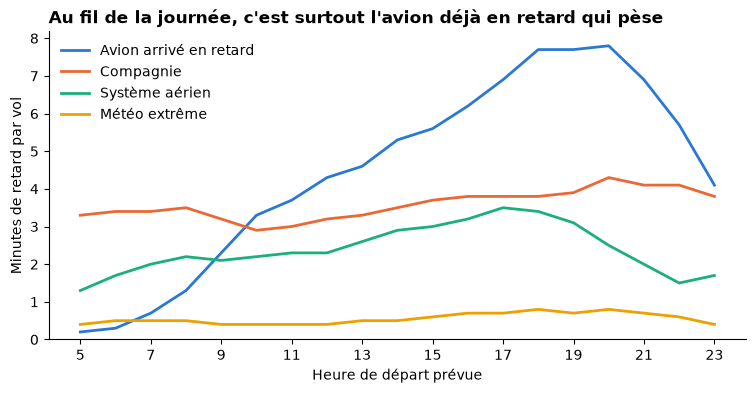

In [32]:
# Sûreté est retirée car elle reste presque nulle. Entre 0 h et 4 h, il y a trop peu de vols.
causes_par_heure = minutes_par_vol("HEURE_DEPART_PREVUE").loc[5:].drop(columns="Sûreté")

ax = causes_par_heure.plot(color=COULEURS_CAUSES, linewidth=2)
ax.set_title("Au fil de la journée, c'est surtout l'avion déjà en retard qui pèse")
ax.set_xlabel("Heure de départ prévue")
ax.set_ylabel("Minutes de retard par vol")
ax.set_ylim(bottom=0)
ax.set_xticks(range(5, 24, 2))
ax.legend(title=None, frameon=False)
plt.show()

**Constat :** entre 6 h et 20 h, les minutes dues à un avion déjà en retard passent de 0,3 à 7,8 par vol, alors que les autres causes bougent bien moins. Cela confirme que les retards s'accumulent au fil de la journée. Entre 0 h et 4 h, il y a trop peu de vols pour conclure.

### Pourquoi les vols sont-ils annulés ?

Selon la description du jeu de données, A = compagnie, B = météo, C = système aérien et D = sûreté. On regarde la part de vols annulés par raison, pour chaque mois.

In [33]:
noms_annulations = {"A": "Compagnie", "B": "Météo", "C": "Système aérien", "D": "Sûreté"}

(pd.crosstab(flights["MONTH"], flights["CANCELLATION_REASON"]).div(flights.groupby("MONTH").size(), axis=0) * 100).rename(columns=noms_annulations).round(2)

CANCELLATION_REASON,Compagnie,Météo,Système aérien,Sûreté
MONTH,,,,
1,0.61,1.49,0.44,0.0
2,0.66,3.60,0.53,0.0
3,0.49,1.36,0.32,0.0
4,0.37,0.37,0.19,0.0
5,0.40,0.56,0.18,0.0
6,0.72,0.66,0.43,0.0
7,0.50,0.17,0.26,0.0
8,0.46,0.26,0.27,0.0
9,0.23,0.11,0.10,0.0


In [34]:
flights["CANCELLATION_REASON"].map(noms_annulations).value_counts(normalize=True).mul(100).round(1)

CANCELLATION_REASON
Météo             54.3
Compagnie         28.1
Système aérien    17.5
Sûreté             0.0
Name: proportion, dtype: float64

**Constat :** la météo est la première raison d'annulation sur l'année (54,3 %), et 3,60 points sur les 4,78 % de vols annulés en février. L'hypothèse de la météo d'hiver est donc confirmée pour les annulations de février.

### Certaines compagnies font-elles nettement mieux que d'autres ?

On compare la part de vols en retard, la part d'annulations et les minutes de retard attribuées à la compagnie elle-même.

In [35]:
airlines = pd.read_csv("../data/raw/airlines.csv")
noms_compagnies = airlines.set_index("IATA_CODE")["AIRLINE"]

par_compagnie = flights.groupby("AIRLINE").agg(
    vols=("AIRLINE", "size"),
    pct_annules=("CANCELLED", "mean"),
)
par_compagnie["pct_annules"] = (par_compagnie["pct_annules"] * 100).round(2)
par_compagnie["pct_en_retard"] = (flights[arrive].groupby("AIRLINE")["EN_RETARD"].mean() * 100).round(1)
par_compagnie["minutes_compagnie"] = minutes_par_vol("AIRLINE")["Compagnie"]

par_compagnie.rename(index=noms_compagnies).sort_values("pct_en_retard")

,vols,pct_annules,pct_en_retard,minutes_compagnie
AIRLINE,,,,
Hawaiian Airlines Inc.,76272,0.22,11.3,2.6
Alaska Airlines Inc.,172521,0.39,13.0,2.0
Delta Air Lines Inc.,875881,0.44,13.6,3.1
American Airlines Inc.,725984,1.50,18.3,3.9
Skywest Airlines Inc.,588353,1.69,18.7,3.5
US Airways Inc.,198715,2.05,18.8,3.3
Southwest Airlines Co.,1261855,1.27,19.0,3.1
Virgin America,61903,0.86,19.2,2.1
Atlantic Southeast Airlines,571977,2.66,19.7,4.3


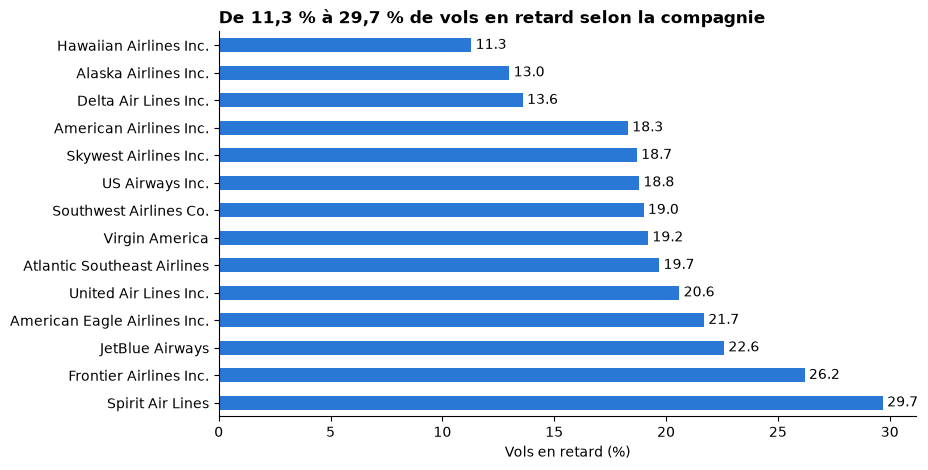

In [36]:
retard_compagnies = par_compagnie.rename(index=noms_compagnies)["pct_en_retard"].sort_values(ascending=False)

ax = retard_compagnies.plot.barh(color=BLEU, figsize=(9, 5))
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("De 11,3 % à 29,7 % de vols en retard selon la compagnie")
ax.set_xlabel("Vols en retard (%)")
ax.set_ylabel("")
plt.show()

**Constat :** la part de vols en retard va de 11,3 % (Hawaiian) à 29,7 % (Spirit). Delta reste à 13,6 % avec 875 881 vols : être une grande compagnie n'empêche donc pas d'être ponctuel. American Eagle annule le plus (5,10 %).

Les minutes attribuées à la compagnie elle-même varient bien moins : Spirit (4,1) est au niveau de United (4,4), alors que Spirit a bien plus de vols en retard.

**Limite :** les compagnies ne volent pas aux mêmes endroits. Cet écart ne mesure donc pas uniquement leur qualité.

### Juin : quelques très mauvais jours, ou tout le mois ?

Pour chaque jour de l'année, on calcule la part de vols en retard. Puis on résume les jours de chaque mois : un jour médian, le pire jour, et le nombre de jours avec au moins 30 % de vols en retard.

In [37]:
retard_par_jour = flights[arrive].groupby(["MONTH", "DAY"])["EN_RETARD"].mean() * 100

retard_par_jour.groupby("MONTH").agg(
    jour_median="median",
    pire_jour="max",
    jours_30_pct=lambda jours: (jours >= 30).sum(),
).round(1)

,jour_median,pire_jour,jours_30_pct
MONTH,,,
1,16.7,49.3,5
2,23.4,37.0,4
3,16.4,41.3,4
4,14.8,31.4,2
5,18.3,32.1,1
6,23.7,35.5,4
7,19.2,35.8,3
8,19.1,34.8,2
9,11.6,27.3,0


**Constat :** juin a le jour médian le plus élevé de l'année (23,7 %), mais pas le pire jour : janvier monte à 49,3 %. Juin est donc mauvais sur tout le mois, et pas à cause de quelques jours catastrophiques.

### Juin : le problème vient-il de certains aéroports ?

On compare juin au reste de l'année, aéroport de départ par aéroport de départ, et on regarde les 20 plus gros aéroports.

In [38]:
gros_aeroports = flights["ORIGIN_AIRPORT"].value_counts().head(20).index
vols_gros_aeroports = flights[arrive & flights["ORIGIN_AIRPORT"].isin(gros_aeroports)]

juin_par_aeroport = pd.DataFrame({
    "juin": vols_gros_aeroports[vols_gros_aeroports["MONTH"] == 6].groupby("ORIGIN_AIRPORT")["EN_RETARD"].mean() * 100,
    "autres_mois": vols_gros_aeroports[vols_gros_aeroports["MONTH"] != 6].groupby("ORIGIN_AIRPORT")["EN_RETARD"].mean() * 100,
})
juin_par_aeroport["ecart"] = juin_par_aeroport["juin"] - juin_par_aeroport["autres_mois"]

juin_par_aeroport.sort_values("ecart", ascending=False).round(1)

,juin,autres_mois,ecart
ORIGIN_AIRPORT,,,
ORD,33.6,22.1,11.5
IAH,30.8,19.8,11.0
EWR,30.0,20.0,10.0
BWI,29.4,21.3,8.2
MCO,26.5,19.1,7.4
CLT,26.7,19.7,7.0
LAS,26.5,19.6,6.9
DEN,27.6,21.0,6.6
ATL,21.5,15.3,6.2


**Constat :** juin ne touche pas tous les aéroports de la même façon. ORD, IAH et EWR gagnent environ 10 points ou plus, alors que SEA et SLC bougent à peine et que JFK baisse.

**Conclusion :** c'est compatible avec un phénomène local, comme les orages d'été, sans le prouver. Il faudrait des données météo extérieures à ce fichier pour trancher.

### Nos chiffres et la météo de juin concordent-ils avec des sources extérieures ?

On recalcule le taux de ponctualité comme les chiffres officiels, en comptant les vols annulés et déviés comme non ponctuels. Puis on regarde les pires jours de juin, pour tout le pays et pour Houston.

In [39]:
ponctualite = flights.groupby("MONTH")["ARRIVAL_DELAY"].apply(lambda retards: (retards < 15).mean() * 100).round(1)
vols_iah = flights[arrive & (flights["MONTH"] == 6) & (flights["ORIGIN_AIRPORT"] == "IAH")]

ponctualite.loc[[5, 6]], retard_par_jour.loc[6].nlargest(5).round(1), (vols_iah.groupby("DAY")["EN_RETARD"].mean() * 100).nlargest(3).round(1)

(MONTH
 5    80.5
 6    74.8
 Name: ARRIVAL_DELAY, dtype: float64,
 DAY
 18    35.5
 15    32.1
 16    31.0
 17    30.5
 27    27.4
 Name: EN_RETARD, dtype: float64,
 DAY
 17    79.5
 16    63.5
 30    54.9
 Name: EN_RETARD, dtype: float64)

**Constat :** on retrouve les chiffres publiés, 80,5 % en mai et 74,8 % en juin ([résumé du rapport officiel](https://www.travelpulse.com/news/airlines-airports/airlines-on-time-performance-up-but-so-are-complaints)). Les pires jours nationaux de juin sont du 15 au 18, et Houston atteint son pire jour le 17, pendant la [tempête tropicale Bill (15-22 juin)](https://www.wpc.ncep.noaa.gov/tropical/rain/bill2015.html). L'Illinois a aussi connu [son mois de juin le plus pluvieux jamais enregistré](https://www.weather.gov/ilx/June_2015_hvyrain).

**Conclusion :** la météo est une explication probable d'une partie de juin, mais ce n'est pas une preuve. Le même rapport indique une ponctualité encore plus basse en juin 2014 (71,8 %) : juin 2015 n'est donc pas un cas isolé.

### Quels aéroports posent le plus de problèmes sur l'année ?

Pour chaque aéroport, on regarde la part de vols qui en partent avec au moins 15 minutes de retard, la part de vols qui y arrivent avec au moins 15 minutes de retard, et la part de vols annulés au départ. On affiche les 30 plus gros aéroports : les petits aéroports ont trop peu de vols pour une comparaison fiable.

In [40]:
par_aeroport = flights.groupby("ORIGIN_AIRPORT").agg(
    vols=("ORIGIN_AIRPORT", "size"),
    pct_annules=("CANCELLED", "mean"),
)
par_aeroport["pct_annules"] = (par_aeroport["pct_annules"] * 100).round(2)
par_aeroport["pct_depart_retard"] = (flights.loc[a_un_depart, "DEPARTURE_DELAY"].ge(15).groupby(flights.loc[a_un_depart, "ORIGIN_AIRPORT"]).mean() * 100).round(1)
par_aeroport["pct_arrivee_retard"] = (flights[arrive].groupby("DESTINATION_AIRPORT")["EN_RETARD"].mean() * 100).round(1)
par_aeroport["ville"] = airports.set_index("IATA_CODE")["CITY"]

par_aeroport.nlargest(30, "vols").sort_values("pct_depart_retard", ascending=False)

,vols,pct_annules,pct_depart_retard,pct_arrivee_retard,ville
ORIGIN_AIRPORT,,,,,
BWI,94101,1.65,24.1,17.7,Baltimore
MDW,88503,2.22,23.9,16.7,Chicago
ORD,313536,2.74,23.4,20.5,Chicago
DAL,65629,1.37,23.3,17.8,Dallas
HOU,56760,1.41,23.2,18.3,Houston
EWR,111394,2.88,23.2,22.0,Newark
MIA,75299,1.06,22.6,20.1,Miami
DEN,214191,1.01,22.2,19.1,Denver
LGA,108195,4.30,22.0,25.5,New York


**Constat :** parmi les 30 plus gros aéroports, la part de départs en retard va de 12,4 % (Salt Lake City) à 24,1 % (Baltimore). New York LaGuardia est le pire à l'arrivée (25,5 %) et annule le plus (4,30 %). Atlanta, le plus gros aéroport, reste à 17,3 %.

**Limite :** un aéroport accueille surtout certaines compagnies, et les écarts entre aéroports peuvent donc aussi venir d'elles.

### Les plus gros aéroports sont-ils les moins ponctuels ?

On mesure le lien entre la taille et le retard avec une corrélation de rang, sur les aéroports d'au moins 10 000 vols au départ. Elle va de -1 à 1 : 0 veut dire aucun lien, et 1 veut dire que le retard augmente toujours avec la taille.

In [41]:
aeroports_comparables = par_aeroport[par_aeroport["vols"] >= 10_000]

len(aeroports_comparables), aeroports_comparables["vols"].rank().corr(aeroports_comparables["pct_depart_retard"].rank()).round(2)

(80, np.float64(0.56))

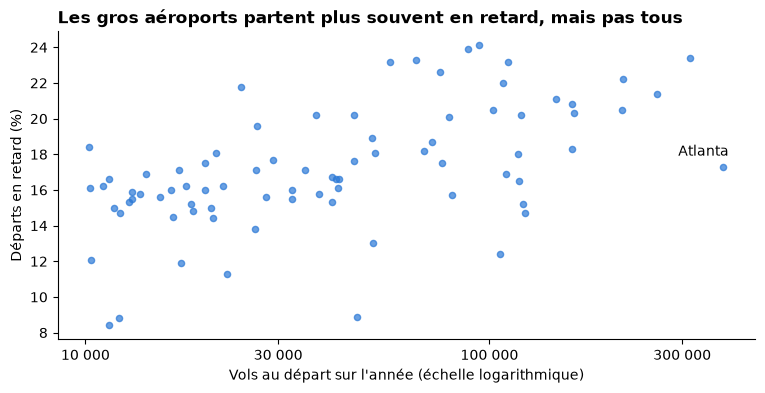

In [42]:
ax = aeroports_comparables.plot.scatter(x="vols", y="pct_depart_retard", color=BLEU, alpha=0.7, logx=True)
ax.annotate("Atlanta", (aeroports_comparables.loc["ATL", "vols"], aeroports_comparables.loc["ATL", "pct_depart_retard"]), xytext=(4, 8), textcoords="offset points", ha="right")
ax.set_xticks([10_000, 30_000, 100_000, 300_000], ["10 000", "30 000", "100 000", "300 000"])
ax.minorticks_off()
ax.set_title("Les gros aéroports partent plus souvent en retard, mais pas tous")
ax.set_xlabel("Vols au départ sur l'année (échelle logarithmique)")
ax.set_ylabel("Départs en retard (%)")
plt.show()

**Constat :** sur 80 aéroports, la corrélation est de 0,56 : les gros aéroports ont tendance à avoir plus de départs en retard, mais la taille n'explique pas tout, comme le montre Atlanta.

## 3. Storyboard

Le plan de l'histoire racontée dans l'app : une page, une question, un message.

| Page | Question | Message clé | Visuel envisagé |
|---|---|---|---|
| 1. L'essentiel | Quelle est l'ampleur ? | Près d'un vol sur cinq n'arrive pas à l'heure | 4 chiffres clés et une barre « 100 vols » |
| 2. Quand ? | À quel moment le risque monte-t-il ? | Le risque grimpe de 9 % à 6 h à 26 % à 20 h, et février et juin sont les mois les plus difficiles | Courbe par heure et barres par mois |
| 3. Pourquoi ? | D'où viennent les retards ? | La première cause est l'effet domino : un avion en retard repart en retard | Barres des causes et courbe de l'effet domino par heure |
| 4. Avec qui et où ? | Qu'est-ce qui change le risque ? | La compagnie et l'aéroport comptent, mais la taille n'explique pas tout | Classement des compagnies et carte des aéroports |

**Indicateur principal :** la part de vols en retard de 15 minutes ou plus.

**À nuancer à l'écran :** les écarts entre compagnies et aéroports ne sont pas une note de qualité, la météo de juin est une explication probable mais pas prouvée, la colonne « météo extrême » sous-estime la météo, et tous les chiffres portent uniquement sur 2015.

### Le risque de retard monte-t-il vraiment au fil de la journée ?

La page 2 a besoin de la part de vols en retard par heure de départ prévue. Jusqu'ici, on n'avait que des minutes par heure. On garde les heures d'au moins 10 000 vols arrivés : de 1 h à 4 h, il y a trop peu de vols pour une comparaison fiable.

In [43]:
par_heure = flights[arrive].groupby("HEURE_DEPART_PREVUE")["EN_RETARD"].agg(vols="size", pct_en_retard="mean")
par_heure["pct_en_retard"] = (par_heure["pct_en_retard"] * 100).round(1)

par_heure[par_heure["vols"] >= 10_000]

,vols,pct_en_retard
HEURE_DEPART_PREVUE,,
0,14504,15.9
5,115647,7.3
6,398508,9.0
7,387719,11.2
8,374828,12.9
9,346299,14.2
10,366008,15.4
11,352601,16.4
12,349867,17.6


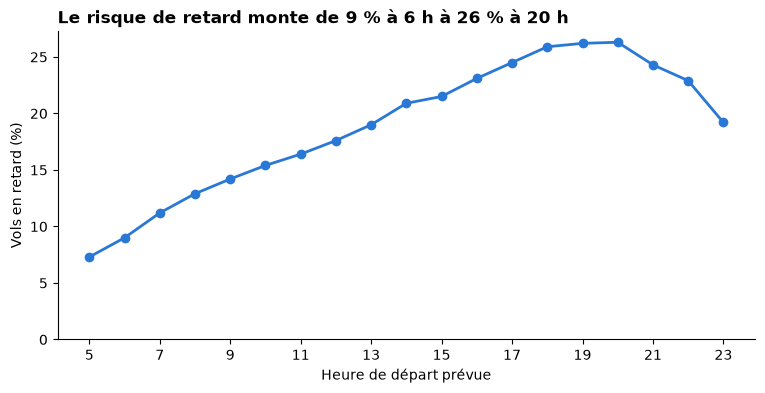

In [44]:
# Le graphique commence à 5 h : avant, il y a trop peu de vols pour comparer.
ax = par_heure.loc[5:, "pct_en_retard"].plot(color=BLEU, linewidth=2, marker="o")
ax.set_title("Le risque de retard monte de 9 % à 6 h à 26 % à 20 h")
ax.set_xlabel("Heure de départ prévue")
ax.set_ylabel("Vols en retard (%)")
ax.set_ylim(bottom=0)
ax.set_xticks(range(5, 24, 2))
plt.show()

**Constat :** la part de vols en retard monte presque sans interruption, de 7,3 % à 5 h et 9,0 % à 6 h jusqu'à 26,3 % à 20 h, puis redescend à 19,2 % à 23 h.

### Le risque du soir touche-t-il toutes les compagnies ?

Le filtre de la page 2 n'a d'intérêt que si la réponse est lisible pour chaque compagnie. On compare donc 6 h et 20 h.

In [45]:
matin_soir = flights[arrive & flights["HEURE_DEPART_PREVUE"].isin([6, 20])]
retard_matin_soir = (matin_soir.groupby(["AIRLINE", "HEURE_DEPART_PREVUE"])["EN_RETARD"].mean() * 100).unstack().round(1)
retard_matin_soir["vols_20h"] = matin_soir[matin_soir["HEURE_DEPART_PREVUE"] == 20].groupby("AIRLINE").size()

retard_matin_soir.rename(index=noms_compagnies).sort_values(20)

HEURE_DEPART_PREVUE,6,20,vols_20h
AIRLINE,,,
Hawaiian Airlines Inc.,1.9,12.8,2877
Alaska Airlines Inc.,7.2,15.5,6039
Delta Air Lines Inc.,7.3,19.7,29172
Skywest Airlines Inc.,9.8,20.2,22281
Virgin America,5.5,23.5,2412
American Eagle Airlines Inc.,15.5,23.7,14435
American Airlines Inc.,9.9,24.9,36413
US Airways Inc.,10.0,25.7,9936
Atlantic Southeast Airlines,12.2,26.3,18902


**Constat :** le risque est plus élevé à 20 h qu'à 6 h pour les 14 compagnies, mais pas avec la même ampleur : +8,2 points pour American Eagle, +25,9 points pour Southwest. Le filtre par compagnie de la page 2 a donc un intérêt.

**Limite :** ces écarts ne mesurent pas que la compagnie, car leurs réseaux et leurs horaires sont différents.

### Tous les pourcentages ont-ils la même base ?

Le 18,3 % de la vue d'ensemble compte tous les vols, alors que les tableaux par mois, compagnie et heure ne comptent que les vols arrivés. On mesure l'écart entre les deux.

In [46]:
pd.Series({
    "sur tous les vols": flights["EN_RETARD"].mean(),
    "sur les vols arrivés": flights.loc[arrive, "EN_RETARD"].mean(),
}).mul(100).round(2)

sur tous les vols       18.28
sur les vols arrivés    18.61
dtype: float64

**Constat :** l'écart est de 0,33 point (18,28 % contre 18,61 %). Il vient des vols annulés et déviés, qui n'ont pas de retard à l'arrivée.

**Choix :** la page 1 garde 18,3 % sur tous les vols, pour que ses 4 catégories fassent 100 %. Les détails par heure, mois et compagnie portent sur les vols arrivés, et l'app l'indiquera sous les graphiques.

### L'effet domino se voit-il sur un même avion ?

Les causes déclarées disent que l'avion arrivé en retard pèse lourd. On peut le vérifier autrement, grâce au numéro d'immatriculation : suivre un même avion dans la journée, et comparer ses vols selon que le vol précédent a fini en retard ou non.

In [47]:
avion_jour = ["TAIL_NUMBER", "MONTH", "DAY"]
vols_avion = (
    flights[arrive & flights["TAIL_NUMBER"].notna()]
    .sort_values(avion_jour + ["SCHEDULED_DEPARTURE"], kind="stable")
    .copy()
)
vols_avion["PRECEDENT_EN_RETARD"] = vols_avion.groupby(avion_jour)["EN_RETARD"].shift()
vols_avion["PRECEDENTE_ARRIVEE"] = vols_avion.groupby(avion_jour)["DESTINATION_AIRPORT"].shift()

# On garde les vols dont l'avion arrive bien de l'aéroport où il repart : sinon il manque un vol dans la chaîne.
suivis = vols_avion[vols_avion["PRECEDENTE_ARRIVEE"] == vols_avion["ORIGIN_AIRPORT"]]
apres_midi = suivis[suivis["HEURE_DEPART_PREVUE"].between(16, 18)]

pd.DataFrame({
    "vols": suivis.groupby("PRECEDENT_EN_RETARD").size(),
    "pct_en_retard": (suivis.groupby("PRECEDENT_EN_RETARD")["EN_RETARD"].mean() * 100).round(1),
    "pct_en_retard_16h_18h": (apres_midi.groupby("PRECEDENT_EN_RETARD")["EN_RETARD"].mean() * 100).round(1),
})

,vols,pct_en_retard,pct_en_retard_16h_18h
PRECEDENT_EN_RETARD,,,
False,3601702,11.3,13.1
True,710732,64.5,68.5


**Constat :** quand le vol précédent du même avion est arrivé en retard, le vol suivant l'est dans 64,5 % des cas, contre 11,3 % sinon. L'heure n'explique pas cet écart : entre 16 h et 18 h, on trouve 68,5 % contre 13,1 %.

**Limite :** c'est un lien, pas une preuve à lui seul, car un même orage peut retarder les deux vols. Sont exclus les vols sans vol précédent le même jour, et ceux dont l'avion ne repart pas de l'aéroport où il vient d'atterrir : il reste 4 312 434 vols sur 5 714 008 vols arrivés.